# Data Analysis with Pandas: the Eurovision Song Contest as cultural data

*Cultural Data Analysis, week 2 — lecture notebook (full version). Nothing needs to be filled in here; the workshop notebook is where you write code yourself.*

This week introduces data analysis with Python and the [Pandas](https://pandas.pydata.org/) library. The notebook follows the steps on the slides (part 3, "Using Pandas"): **open → inspect → clean → select, derive & filter → analyze & visualize**, and ends with writing data back to a file.

Two layers run through the notebook:

* the **practical layer**: every operation is a Pandas technique you will use in the workshop notebook and in your own projects;
* the **methods layer**: short *Methods notes* (the indented blocks) highlight the points where a technical step is also a methodological decision.

## Our case: the Eurovision Song Contest

Eurovision is a useful object for cultural data analysis because the contest is itself a "machine" for producing formalized traces: since 1956, every entry comes with a country, a running order, a result, and (since 1957) points awarded by other countries according to rules that changed many times. These traces have been collected by fans and researchers, and they have been analyzed in a small corpus of research literature. Three research questions from that literature guide what we do with the data today:

* **RQ1 — Do expert juries and the public agree?** Since 2016, jury and public (televote) points are published separately. Haan, Dijkstra & Dijkstra (2005) and Kadoić, Žajdela Hrustek & Gligora Marković (2025) compare the two and the latter find that juries are not more consistent than the public and that they regularly move the winner away from the public's choice.
* **RQ2 — Does the position in the running order matter?** Bruine de Bruin (2005) finds that performers who appear later receive better evaluations, in Eurovision as in figure skating; Haan et al. (2005) show that results depend on such factors unrelated to the quality of a song, and that expert juries are less affected than the public.
* **RQ3 — What happened to the language of entries after the national-language rule was abolished in 1999?** A classic cultural-policy question: English as lingua franca versus national languages.

> **Methods note: questions first.** The operations below (sorting, filtering, grouping, correlating) are generic and only become an *analysis* through the question they try to answer. Each section states which question it addresses and what the result can and cannot show. Notice also the different *styles* of question: RQ3 is descriptive (what happened?), RQ1 is comparative, and RQ2 asks for an explanation (why?) that, as we will see, this kind of data cannot really deliver on its own.

**References**

* Bruine de Bruin, W. (2005). Save the last dance for me: Unwanted serial position effects in jury evaluations. *Acta Psychologica, 118*(3), 245–260.
* Burgoyne, J. A., Spijkervet, J., & Baker, D. J. (2023). Measuring the Eurovision Song Contest: A living dataset for real-world MIR. *Proceedings of ISMIR 2023*, 817–823. [PDF](https://archives.ismir.net/ismir2023/paper/000097.pdf)
* Ginsburgh, V., & Noury, A. G. (2008). The Eurovision Song Contest. Is voting political or cultural? *European Journal of Political Economy, 24*(1), 41–52.
* Haan, M. A., Dijkstra, S. G., & Dijkstra, P. T. (2005). Expert judgment versus public opinion – Evidence from the Eurovision Song Contest. *Journal of Cultural Economics, 29*(1), 59–78.
* Kadoić, N., Žajdela Hrustek, N., & Gligora Marković, M. (2025). Eurovision Song Contest: Can juries assess the quality of songs objectively? *Central European Journal of Operations Research, 33*(3), 859–890. https://doi.org/10.1007/s10100-025-00971-2

## Setup

A library is a set of pre-written code that we load to perform common tasks, so that we do not have to write everything from scratch. We import Pandas under the usual abbreviation `pd`, and two visualization libraries for later. Libraries change over time, and sometimes we have to account for that.

In [1]:
import pandas as pd
if pd.__version__ < "3":                  # pandas 3 behaves like this by default
    pd.options.mode.copy_on_write = True  # new DataFrames derived from existing ones are proper copies

# for visualization:
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Getting the data

Our data come from the [Unofficial Eurovision Song Contest Dataset](https://github.com/EurovisionAPI/dataset), a GitHub repository maintained by a fan and updated once a year (it currently covers 1956 to 2026). It compiles information from fan websites such as [ESC Home](https://eschome.net/) and [Eurovision World](https://eurovisionworld.com). It is not a CSV file but a folder structure with thousands of small files:

```
data/senior/2025/contest.json                      # host city, slogan, presenters
data/senior/2025/rounds/final.json                 # running order, places, points, votes from each country
data/senior/2025/rounds/semifinal1.json
data/senior/2025/contestants/0_at/contestant.json  # artist, song, writers, broadcaster, ...
data/senior/2025/contestants/0_at/lyrics/o_english.txt
```

The cell below downloads the whole repository as a zip archive, unpacks it, walks through the folders, and builds one table with **one row per entry** (a song by a country in a year). The columns follow the research dataset by Spijkervet and Burgoyne et al. (2023), which stops in 2023, so that results can be compared with the literature. The table is saved as `eurovision_contestants.csv`.

**Thinking, not writing.** You are not expected to be able to write a cell like this in week 2. You are expected to think about the operations: what is one row? what is left out? where are decisions made? This is the same skill you need when an AI assistant writes code for you - the question is never only whether the code runs, but what it does with the data.

In [2]:
# --- Build a flat table of Eurovision entries from the "Unofficial Eurovision Song Contest Dataset" ---
# The dataset sits on GitHub as thousands of small JSON and text files (one folder per year,
# one folder per entry). We download it once as a zip archive, unpack it, and then walk through
# the folders to collect one row per entry. The result is saved as a CSV file.

import json, glob, os, zipfile, urllib.request
import pandas as pd

ZIP_URL  = "https://github.com/EurovisionAPI/dataset/archive/refs/heads/main.zip"
ZIP_FILE = "eurovision_dataset.zip"
FOLDER   = "eurovision_dataset"          # the archive unpacks into FOLDER/dataset-main/...
OUT_FILE = "eurovision_contestants.csv"

# 1. download and unpack (skipped if we already did it in this session)
if not os.path.exists(FOLDER):
    urllib.request.urlretrieve(ZIP_URL, ZIP_FILE)
    with zipfile.ZipFile(ZIP_FILE) as archive:
        archive.extractall(FOLDER)

base = os.path.join(FOLDER, "dataset-main", "data")
country_names = json.load(open(os.path.join(base, "countries.json"), encoding="utf-8"))

def join(values):
    """Turn a list of names into one string separated by ';' (or None if there is no list)."""
    return ";".join(values) if values else None

def youtube_link(urls):
    """The dataset stores embed links; we rewrite the first one as a normal YouTube URL."""
    if not urls:
        return None
    video_id = urls[0].rstrip("/").split("/")[-1]
    return f"https://www.youtube.com/watch?v={video_id}"

rows = []
for year_folder in sorted(glob.glob(os.path.join(base, "senior", "*"))):
    year = int(os.path.basename(year_folder))

    # 2. results per round: a dictionary that maps a contestant id to its running order, place and points
    results = {}
    final_date = None
    for round_file in glob.glob(os.path.join(year_folder, "rounds", "*.json")):
        round_name = os.path.basename(round_file).replace(".json", "")      # final, semifinal, semifinal1, semifinal2
        stage = "final" if round_name == "final" else "sf"
        round_data = json.load(open(round_file, encoding="utf-8"))
        for perf in round_data.get("performances") or []:                  # 2020 has no performances: the contest was cancelled
            r = results.setdefault(perf["contestantId"], {})
            if stage == "sf":
                r["sf_num"] = {"semifinal": 0, "semifinal1": 1, "semifinal2": 2}[round_name]
            r[f"running_{stage}"] = perf["running"]
            r[f"place_{stage}"] = perf["place"]
            for score in perf.get("scores") or []:                         # 'total' always; 'public' and 'jury' from 2016
                label = {"total": "points", "public": "points_tele", "jury": "points_jury"}[score["name"]]
                r[f"{label}_{stage}"] = score["points"]
        if round_name == "final":
            final_date = round_data.get("date")

    # 3. one row per contestant, combining metadata, results and lyrics
    for entry_folder in sorted(glob.glob(os.path.join(year_folder, "contestants", "*"))):
        info = json.load(open(os.path.join(entry_folder, "contestant.json"), encoding="utf-8"))
        res = results.get(info["id"], {})

        # original lyrics are stored as lyrics/o_<language>.txt; the language is part of the file name
        lyric_files = sorted(glob.glob(os.path.join(entry_folder, "lyrics", "o_*.txt")))
        languages = []
        for f in lyric_files:
            name = os.path.basename(f)[2:-4]                   # e.g. "french,english" or "greek_ellinika"
            for lang in name.split(","):
                lang = lang.split("_")[0]                      # drop variants such as "_ellinika" or "_eurovision"
                if lang not in languages:
                    languages.append(lang)
        lyrics = open(lyric_files[0], encoding="utf-8").read() if lyric_files else None

        rows.append({
            "year": year,
            "to_country_id": info["country"].lower(),
            "to_country": country_names.get(info["country"], info["country"]),
            "performer": info["artist"],
            "song": info["song"],
            "sf_num": res.get("sf_num"),
            "running_final": res.get("running_final"),
            "running_sf": res.get("running_sf"),
            "place_final": res.get("place_final"),
            "points_final": res.get("points_final"),
            "place_sf": res.get("place_sf"),
            "points_sf": res.get("points_sf"),
            "points_tele_final": res.get("points_tele_final"),
            "points_jury_final": res.get("points_jury_final"),
            "points_tele_sf": res.get("points_tele_sf"),
            "points_jury_sf": res.get("points_jury_sf"),
            "composers": join(info.get("composers")),
            "lyricists": join(info.get("lyricists")),
            "writers": join(info.get("writers")),
            "lyrics": lyrics,
            "language": ";".join(languages) if languages else None,
            "youtube_url": youtube_link(info.get("videoUrls")),
            "date_final": final_date,
        })

df_built = pd.DataFrame(rows)
df_built.to_csv(OUT_FILE, index=False)
print(len(df_built), "entries saved to", OUT_FILE)

1830 entries saved to eurovision_contestants.csv


> **Methods note: data is made.** The table you now have did not exist before this cell ran. The archive behind it is maintained by fans, without a formal licence or institutional guarantee, and compiled from other fan sites. The flattening involved decisions: one row per entry (not per country, not per song); semi-finals coded 0, 1, or 2; translations dropped; where several versions of the original lyrics exist (Greek in Latin and Greek script, for example) the first file alphabetically is kept; the points each country gave to each other country are left out entirely (we'll come back to this in week 6). Every dataset you will ever download has a cell like this behind it, written by someone else, usually without the comments.

If the download does not work (GitHub unreachable, no internet), a copy of the CSV file is in our shared Drive folder. Mount your Drive and point `OUT_FILE` to it:

In [3]:
# from google.colab import drive
# drive.mount('/content/drive')
# OUT_FILE = '/content/drive/MyDrive/CDA/Week 2 - Pandas/eurovision_contestants.csv'    # adapt to your path

## 2. Opening and inspecting

Reading a CSV file into a DataFrame is a single function call: `pd.read_csv()` with the file path. Pandas takes care of opening and closing the file. We store the result in the variable `df`. Calling the variable in the last line of a cell shows the first and last five rows.

In [4]:
df = pd.read_csv(OUT_FILE)
df

,year,to_country_id,to_country,performer,song,sf_num,running_final,running_sf,place_final,points_final,...,points_jury_final,points_tele_sf,points_jury_sf,composers,lyricists,writers,lyrics,language,youtube_url,date_final
0,1956,ch,Switzerland,Lys Assia,Refrain,NaN,9.0,NaN,1.0,NaN,...,NaN,NaN,NaN,Géo Voumard,Émile Gardaz,NaN,"Refrain\n\n(Refrain d'amour…)\n\nRefrain, coul...",french,https://www.youtube.com/watch?v=EXS3v09LKS8,1956-05-24
1,1956,de,Germany,Freddy Quinn,So geht das jede Nacht,NaN,11.0,NaN,NaN,NaN,...,NaN,NaN,NaN,Lotar Olias,Peter Moesser,NaN,So geht das jede Nacht\n\nAm Sonntag mit Jimmy...,german,https://www.youtube.com/watch?v=DJFGwPVKfyk,1956-05-24
2,1956,fr,France,Dany Dauberson,Il est là,NaN,12.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,Simone Vallauris,"Il est là\n\nJe ne peux changer ma vie, il est...",french,https://www.youtube.com/watch?v=c4EpfbOZVZA,1956-05-24
3,1956,lu,Luxembourg,Michèle Arnaud,Les Amants de minuit,NaN,13.0,NaN,NaN,NaN,...,NaN,NaN,NaN,Simone Laurencin,Jacques Lassry,NaN,Les Amants de minuit\n\nLes amants de minuit p...,french,https://www.youtube.com/watch?v=r99NL_NvJps,1956-05-24
4,1956,it,Italy,Tonina Torielli,Amami se vuoi,NaN,14.0,NaN,NaN,NaN,...,NaN,NaN,NaN,Vittorio Mascheroni,Mario Panzeri,NaN,Amami se vuoi\n\nMi piace tanto accarezzarti\n...,italian,https://www.youtube.com/watch?v=k19AnMpqnE4,1956-05-24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1825,2026,fi,Finland,Linda Lampenius & Pete Parkkonen,Liekinheitin,1.0,17.0,7.0,6.0,279.0,...,141.0,100.0,127.0,NaN,NaN,Antti Riihimäki;Lauri Halavaara;Linda Lampeniu...,Liekinheitin\n\nOis viisaampi häipyy täält\nMi...,finnish,https://www.youtube.com/watch?v=CmPkrjTtrwE,2026-05-16
1826,2026,dk,Denmark,Søren Torpegaard Lund,Før vi går hjem,2.0,1.0,10.0,7.0,243.0,...,165.0,75.0,124.0,NaN,NaN,Clara Sofie Fabricius;Søren Torpegaard Lund;Th...,Før vi går hjem\n\nMin krop den skriger\nKan d...,danish,https://www.youtube.com/watch?v=5lBWuEZ2qyo,2026-05-16
1827,2026,md,Moldova,Satoshi,"Viva, Moldova",1.0,16.0,1.0,8.0,226.0,...,43.0,146.0,62.0,Andrei Vulpe;Cătălin Temciuc;Vlad Sabajuc;Vasi...,Vlad Sabajuc,NaN,"Viva, Moldova\n\nViva Moldova, aloha\nAdio, vi...",multilingual,https://www.youtube.com/watch?v=CKV15yxAsIQ,2026-05-16
1828,2026,ua,Ukraine,Leléka,Ridnym,2.0,7.0,12.0,9.0,221.0,...,54.0,99.0,75.0,Adama Cefalu;Jakob Hegner;Viktoriia Leléka;Yar...,Adama Cefalu;Viktoriia Leléka,NaN,Ridnym\n\nGreen into rust\nTrust in the change...,english;ukrainian;ukrainska;українська,https://www.youtube.com/watch?v=JYHhcKhzE-o,2026-05-16


`head()` and `tail()` show as many rows from the beginning or the end as we want (five by default), and `sort_values()` lets us look at the data from a specific angle, for example the entries with the most points.

In [5]:
df.head(3)

,year,to_country_id,to_country,performer,song,sf_num,running_final,running_sf,place_final,points_final,...,points_jury_final,points_tele_sf,points_jury_sf,composers,lyricists,writers,lyrics,language,youtube_url,date_final
0,1956,ch,Switzerland,Lys Assia,Refrain,NaN,9.0,NaN,1.0,NaN,...,NaN,NaN,NaN,Géo Voumard,Émile Gardaz,NaN,"Refrain\n\n(Refrain d'amour…)\n\nRefrain, coul...",french,https://www.youtube.com/watch?v=EXS3v09LKS8,1956-05-24
1,1956,de,Germany,Freddy Quinn,So geht das jede Nacht,NaN,11.0,NaN,NaN,NaN,...,NaN,NaN,NaN,Lotar Olias,Peter Moesser,NaN,So geht das jede Nacht\n\nAm Sonntag mit Jimmy...,german,https://www.youtube.com/watch?v=DJFGwPVKfyk,1956-05-24
2,1956,fr,France,Dany Dauberson,Il est là,NaN,12.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,Simone Vallauris,"Il est là\n\nJe ne peux changer ma vie, il est...",french,https://www.youtube.com/watch?v=c4EpfbOZVZA,1956-05-24


In [6]:
df.sort_values('points_final', ascending=False).head(10)

,year,to_country_id,to_country,performer,song,sf_num,running_final,running_sf,place_final,points_final,...,points_jury_final,points_tele_sf,points_jury_sf,composers,lyricists,writers,lyrics,language,youtube_url,date_final
1438,2017,pt,Portugal,Salvador Sobral,Amar pelos dois,1.0,11.0,9.0,1.0,758.0,...,382.0,197.0,173.0,NaN,NaN,Luísa Sobral,Amar pelos dois\n\nSe um dia alguém perguntar ...,portuguese,https://www.youtube.com/watch?v=Qotooj7ODCM,2017-05-13
1644,2022,ua,Ukraine,Kalush Orchestra,Stefania,1.0,12.0,6.0,1.0,631.0,...,192.0,202.0,135.0,Ihor Didenchuk;Tymofii Muzychuk;Vitalii Duzhyk,Ivan Klymenko;Oleh Psiuk,NaN,Stefania\n\nStefania mamo mamo Stefania\nRozkv...,ukrainian,https://www.youtube.com/watch?v=F1fl60ypdLs,2022-05-14
1449,2017,bg,Bulgaria,Kristian Kostov,Beautiful Mess,2.0,25.0,15.0,2.0,615.0,...,278.0,204.0,199.0,NaN,NaN,Alex Omar;Alexander V. Blay;Borislav Milanov;J...,Beautiful Mess\n\nWhen the world shakes us\nTr...,english,https://www.youtube.com/watch?v=OMmm-G078LM,2017-05-13
1721,2024,ch,Switzerland,Nemo,The Code,2.0,21.0,4.0,1.0,591.0,...,365.0,NaN,NaN,NaN,NaN,Benjamin Jon Alasu;Lasse Midtsian Nymann;Linda...,"The Code\n\nWelcome to the show, let everybody...",english,https://www.youtube.com/watch?v=CO_qJf-nW0k,2024-05-11
1684,2023,se,Sweden,Loreen,Tattoo,1.0,9.0,11.0,1.0,583.0,...,340.0,NaN,NaN,NaN,NaN,Jimmy Jansson;Jimmy Joker;Loreen;Moa Carlebeck...,Tattoo\n\nI don't wanna go\nBut baby we both k...,english,https://www.youtube.com/watch?v=BE2Fj0W4jP4,2023-05-13
1732,2024,hr,Croatia,Baby Lasagna,Rim Tim Tagi Dim,1.0,23.0,7.0,2.0,547.0,...,210.0,NaN,NaN,NaN,NaN,Marko Purišić,"Rim Tim Tagi Dim\n\nAy, I'm a big boy now\nI'm...",english,https://www.youtube.com/watch?v=YIBjarAiAVc,2024-05-11
1396,2016,ua,Ukraine,Jamala,1944,2.0,21.0,14.0,1.0,534.0,...,211.0,152.0,135.0,NaN,NaN,Jamala,1944\n\nWhen strangers are coming\nThey come t...,english;crimean tatar,https://www.youtube.com/watch?v=B-rnM-MwRHY,2016-05-14
1480,2018,il,Israel,Netta,Toy,1.0,22.0,7.0,1.0,529.0,...,212.0,116.0,167.0,Doron Medalie;Jack White;Stav Beger,Doron Medalie;Stav Beger,NaN,"Toy\n\nRee, ouch, he, hm, la\nRee, ouch, he, h...",english,https://www.youtube.com/watch?v=84LBjXaeKk4,2018-05-12
1695,2023,fi,Finland,Käärijä,Cha Cha Cha,1.0,13.0,15.0,2.0,526.0,...,150.0,NaN,NaN,Aleksi Nurmi;Johannes Naukkarinen;Jukka Sorsa,Jere Pöyhönen,NaN,Cha Cha Cha\n\nRankka viikko ja paljon pitkii ...,finnish,https://www.youtube.com/watch?v=l6rS8Dv5g-8,2023-05-13
1605,2021,it,Italy,Måneskin,Zitti e buoni,NaN,24.0,NaN,1.0,524.0,...,206.0,NaN,NaN,NaN,NaN,Damiano David;Ethan Torchio;Thomas Raggi;Victo...,Zitti e buoni\n\nLoro non sanno di che parlo\n...,italian,https://www.youtube.com/watch?v=RVH5dn1cxAQ,2021-05-22


In [7]:
df[['year', 'to_country', 'performer', 'song', 'points_final', 'points_jury_final', 'points_tele_final']]

,year,to_country,performer,song,points_final,points_jury_final,points_tele_final
0,1956,Switzerland,Lys Assia,Refrain,NaN,NaN,NaN
1,1956,Germany,Freddy Quinn,So geht das jede Nacht,NaN,NaN,NaN
2,1956,France,Dany Dauberson,Il est là,NaN,NaN,NaN
3,1956,Luxembourg,Michèle Arnaud,Les Amants de minuit,NaN,NaN,NaN
4,1956,Italy,Tonina Torielli,Amami se vuoi,NaN,NaN,NaN
...,...,...,...,...,...,...,...
1825,2026,Finland,Linda Lampenius & Pete Parkkonen,Liekinheitin,279.0,141.0,138.0
1826,2026,Denmark,Søren Torpegaard Lund,Før vi går hjem,243.0,165.0,78.0
1827,2026,Moldova,Satoshi,"Viva, Moldova",226.0,43.0,183.0
1828,2026,Ukraine,Leléka,Ridnym,221.0,54.0,167.0


In [8]:
df.sort_values('points_final', ascending=False).head(10)[['year', 'to_country', 'performer', 'song', 'points_final', 'points_jury_final', 'points_tele_final']]

,year,to_country,performer,song,points_final,points_jury_final,points_tele_final
1438,2017,Portugal,Salvador Sobral,Amar pelos dois,758.0,382.0,376.0
1644,2022,Ukraine,Kalush Orchestra,Stefania,631.0,192.0,439.0
1449,2017,Bulgaria,Kristian Kostov,Beautiful Mess,615.0,278.0,337.0
1721,2024,Switzerland,Nemo,The Code,591.0,365.0,226.0
1684,2023,Sweden,Loreen,Tattoo,583.0,340.0,243.0
1732,2024,Croatia,Baby Lasagna,Rim Tim Tagi Dim,547.0,210.0,337.0
1396,2016,Ukraine,Jamala,1944,534.0,211.0,323.0
1480,2018,Israel,Netta,Toy,529.0,212.0,317.0
1695,2023,Finland,Käärijä,Cha Cha Cha,526.0,150.0,376.0
1605,2021,Italy,Måneskin,Zitti e buoni,524.0,206.0,318.0


`.info()` tells us how many rows there are, which columns exist, which data type Pandas assigned to each column, how many values are not missing, and how much memory the table takes.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1830 entries, 0 to 1829
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               1830 non-null   int64  
 1   to_country_id      1830 non-null   object 
 2   to_country         1830 non-null   object 
 3   performer          1830 non-null   object 
 4   song               1830 non-null   object 
 5   sf_num             713 non-null    float64
 6   running_final      1475 non-null   float64
 7   running_sf         713 non-null    float64
 8   place_final        1462 non-null   float64
 9   points_final       1461 non-null   float64
 10  place_sf           713 non-null    float64
 11  points_sf          713 non-null    float64
 12  points_tele_final  257 non-null    float64
 13  points_jury_final  257 non-null    float64
 14  points_tele_sf     242 non-null    float64
 15  points_jury_sf     242 non-null    float64
 16  composers          1065 

> **Methods note: what is a row?** Before counting anything, be sure what one row stands for. Here it is an *entry*: one song performed for one country in one year. It is not a country, not an artist, and not a song in the abstract. In 1956 every country sent two songs, so that year has 14 rows for 7 countries; Lys Assia appears twice. Many mistakes in data analysis are mistakes about the unit of analysis. Inspecting also means looking at actual rows, not only at summaries; a viewer such as [Modern CSV](https://www.moderncsv.com/) is useful for that.

In [10]:
df[df['year'] == 1956][['year', 'to_country', 'performer', 'song', 'running_final', 'place_final']]

,year,to_country,performer,song,running_final,place_final
0,1956,Switzerland,Lys Assia,Refrain,9.0,1.0
1,1956,Germany,Freddy Quinn,So geht das jede Nacht,11.0,NaN
2,1956,France,Dany Dauberson,Il est là,12.0,NaN
3,1956,Luxembourg,Michèle Arnaud,Les Amants de minuit,13.0,NaN
4,1956,Italy,Tonina Torielli,Amami se vuoi,14.0,NaN
5,1956,Netherlands,Jetty Paerl,De vogels van Holland,1.0,NaN
6,1956,Switzerland,Lys Assia,Das alte Karussell,2.0,NaN
7,1956,Belgium,Fud Leclerc,Messieurs les noyés de la Seine,3.0,NaN
8,1956,Germany,Walter Andreas Schwarz,Im Wartesaal zum großen Glück,4.0,NaN
9,1956,France,Mathé Altéry,Le Temps perdu,5.0,NaN


## 3. Cleaning

Cleaning means preparing the data for the analysis we want to do: dealing with missing values, correcting data types, selecting and renaming columns. There is no universal correct way of cleaning; it depends on the question, and we often come back to this step later.

Let's start with missing values. `isna()` marks every missing cell, `sum()` counts them per column, and `sort_values()` orders the result. Three chained operations give us an overview that would otherwise take many lines of code.

In [11]:
df.isna().sum().sort_values(ascending=False)

,0
points_tele_sf,1588
points_jury_sf,1588
points_jury_final,1573
points_tele_final,1573
sf_num,1117
points_sf,1117
place_sf,1117
running_sf,1117
writers,1065
lyricists,767


> **Methods note: "missingness" has a history.** Most empty cells in this table are not errors. Semi-finals exist only since 2004; jury and public points are reported separately only since 2016; the 1956 results were never published; the 2020 contest was cancelled, so its 41 entries have no results at all. `dropna()` would delete history, not mistakes. The question to ask is not "how do I get rid of the gaps?" but "which rows are comparable for the question I am asking?"

In [12]:
df[df['year'] == 2020][['year', 'to_country', 'performer', 'song', 'place_final', 'points_final']].head()

,year,to_country,performer,song,place_final,points_final
1564,2020,Albania,Arilena Ara,Fall From The Sky,NaN,NaN
1565,2020,Czechia,Benny Cristo,Kemama,NaN,NaN
1566,2020,Denmark,Ben & Tan,Yes,NaN,NaN
1567,2020,Estonia,Uku Suviste,What Love Is,NaN,NaN
1568,2020,Finland,Aksel,Looking Back,NaN,NaN


Pandas guesses the data type of each column (`object` or `str` is text, `int64` and `float64` are numbers). `datetime64[ns]` is a data type for dates, but Pandas often does not recognise dates correctly. Here, the column `date_final` is text. For anything time-related we convert it with `pd.to_datetime()` and verify the result.

In [13]:
df['date_final'] = pd.to_datetime(df['date_final'])
df['date_final'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 1830 entries, 0 to 1829
Series name: date_final
Non-Null Count  Dtype         
--------------  -----         
1830 non-null   datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 14.4 KB


The `.dt` accessor then gives us the parts of a date. In which months were the finals held? Not sure what `.first()` means? Ask Gemini to explain the code.

In [14]:
df.groupby('year')['date_final'].first().dt.month.value_counts()

,count
date_final,
5,43
3,15
4,13


## 4. Selecting, deriving, and filtering

A single column is selected like a dictionary key and returns a `Series`; a list of column names returns a smaller `DataFrame`. The full table has 23 columns including the complete lyrics, which makes it cumbersome to display, so we work on a selection and keep the original `df` intact.

In [15]:
df['year']

,year
0,1956
1,1956
2,1956
3,1956
4,1956
...,...
1825,2026
1826,2026
1827,2026
1828,2026


In [16]:
columns = ['year', 'to_country_id', 'to_country', 'performer', 'song', 'language', 'sf_num',
           'running_final', 'place_final', 'points_final', 'points_jury_final', 'points_tele_final',
           'place_sf', 'points_sf', 'date_final']
df_sel = df[columns]
df_sel.head()

,year,to_country_id,to_country,performer,song,language,sf_num,running_final,place_final,points_final,points_jury_final,points_tele_final,place_sf,points_sf,date_final
0,1956,ch,Switzerland,Lys Assia,Refrain,french,NaN,9.0,1.0,NaN,NaN,NaN,NaN,NaN,1956-05-24
1,1956,de,Germany,Freddy Quinn,So geht das jede Nacht,german,NaN,11.0,NaN,NaN,NaN,NaN,NaN,NaN,1956-05-24
2,1956,fr,France,Dany Dauberson,Il est là,french,NaN,12.0,NaN,NaN,NaN,NaN,NaN,NaN,1956-05-24
3,1956,lu,Luxembourg,Michèle Arnaud,Les Amants de minuit,french,NaN,13.0,NaN,NaN,NaN,NaN,NaN,NaN,1956-05-24
4,1956,it,Italy,Tonina Torielli,Amami se vuoi,italian,NaN,14.0,NaN,NaN,NaN,NaN,NaN,NaN,1956-05-24


### Deriving new variables

RQ1 asks whether juries and the public agree. To compute anything, the question has to be operationalized. A first attempt: the difference between the jury points and the public points an entry received in the final. Positive values mean the jury liked the song more than the public, negative values the reverse.

In [17]:
df_sel['jury_minus_public'] = df_sel['points_jury_final'] - df_sel['points_tele_final']

columns = ['year', 'to_country', 'performer', 'song', 'place_final', 'points_jury_final', 'points_tele_final', 'jury_minus_public']

display(df_sel.sort_values('jury_minus_public', ascending=False)[columns].head(5))   # the jury's favourites
display(df_sel.sort_values('jury_minus_public')[columns].head(5))                    # the public's favourites

,year,to_country,performer,song,place_final,points_jury_final,points_tele_final,jury_minus_public
1519,2018,Sweden,Benjamin Ingrosso,Dance You Off,7.0,253.0,21.0,232.0
1794,2025,Switzerland,Zoë Më,Voyage,10.0,214.0,0.0,214.0
1502,2018,Austria,Cesár Sampson,Nobody But You,3.0,271.0,71.0,200.0
1560,2019,North Macedonia,Tamara Todevska,Proud,7.0,247.0,58.0,189.0
1478,2017,Australia,Isaiah,Don't Come Easy,9.0,171.0,2.0,169.0


,year,to_country,performer,song,place_final,points_jury_final,points_tele_final,jury_minus_public
1752,2024,Israel,Eden Golan,Hurricane,5.0,52.0,323.0,-271.0
1559,2019,Norway,KEiiNO,Spirit In The Sky,6.0,40.0,291.0,-251.0
1644,2022,Ukraine,Kalush Orchestra,Stefania,1.0,192.0,439.0,-247.0
1769,2025,Israel,Yuval Raphael,New Day Will Rise,2.0,60.0,297.0,-237.0
1418,2016,Russia,Sergey Lazarev,You Are the Only One,3.0,130.0,361.0,-231.0


> **Methods note: operationalization.** "Agreement" has to become something computable, and there is more than one way to do it. The difference of points treats jury and public points as comparable quantities on the same scale. Kadoić et al. (2025) instead correlate the two sets of points per contest. Both are defensible, but they answer slightly different versions of the question, and they can disagree. Whenever you derive a variable, you decide what the concept in your question will mean for the rest of the analysis.

A second derived variable serves RQ3. The `language` column lists the language(s) of the original lyrics, separated by `;` if there are several. We reduce this to three categories with a small function and `.apply()`, which runs the function on every value of the column.

In [18]:
def classify_language(language):
    if ';' in language:
        return 'mixed'
    elif language == 'english':
        return 'english'
    else:
        return 'other'

df_sel['language_type'] = df_sel['language'].apply(classify_language)
df_sel['language_type'].value_counts()

,count
language_type,
other,939
english,738
mixed,153


> **Methods note: categories are decisions.** The three "boxes" compress more than sixty languages because *our* question is about English. A question about regional or minority languages would need other boxes, and "mixed" hides whether a song is mostly English with one line in Ukrainian or the reverse. The dataset's own files incorporate such decisions already - `greek_ellinika` and `greek_ελληνικά` are the same lyrics in two scripts, and the code that built our table merged them.

### Accessing rows and columns by label or position

`.loc` selects by labels (row index and column names), `.iloc` by integer positions. DataCamp has a [good overview](https://www.datacamp.com/tutorial/loc-vs-iloc).

In [19]:
display(df_sel.loc[0:3, ['year', 'to_country', 'performer']])
display(df_sel.iloc[0:3, [0, 2, 3]])

,year,to_country,performer
0,1956,Switzerland,Lys Assia
1,1956,Germany,Freddy Quinn
2,1956,France,Dany Dauberson
3,1956,Luxembourg,Michèle Arnaud


,year,to_country,performer
0,1956,Switzerland,Lys Assia
1,1956,Germany,Freddy Quinn
2,1956,France,Dany Dauberson


### Filtering rows

We select rows with a condition in square brackets: "give me all rows for which the value in this column is equal to this value". The condition itself is a Series of `True`/`False` values.

In [20]:
df_sel[df_sel['to_country'] == 'Netherlands'].sort_values('place_final').head(10)

,year,to_country_id,to_country,performer,song,language,sf_num,running_final,place_final,points_final,points_jury_final,points_tele_final,place_sf,points_sf,date_final,jury_minus_public,language_type
14,1957,nl,Netherlands,Corry Brokken,Net als toen,dutch,NaN,6.0,1.0,31.0,NaN,NaN,NaN,NaN,1957-03-03,NaN,other
34,1959,nl,Netherlands,Teddy Scholten,Een beetje,dutch,NaN,5.0,1.0,21.0,NaN,NaN,NaN,NaN,1959-03-11,NaN,other
200,1969,nl,Netherlands,Lenny Kuhr,De troubadour,dutch,NaN,8.0,1.0,18.0,NaN,NaN,NaN,NaN,1969-03-29,NaN,other
290,1975,nl,Netherlands,Teach-In,Ding-a-dong,english,NaN,1.0,1.0,152.0,NaN,NaN,NaN,NaN,1975-03-22,NaN,english
1523,2019,nl,Netherlands,Duncan Laurence,Arcade,english,2.0,12.0,1.0,498.0,237.0,261.0,1.0,280.0,2019-05-18,-24.0,english
1330,2014,nl,Netherlands,The Common Linnets,Calm After The Storm,english,1.0,24.0,2.0,238.0,NaN,NaN,1.0,150.0,2014-05-10,NaN,english
282,1974,nl,Netherlands,Mouth & MacNeal,I See a Star,english,NaN,12.0,3.0,15.0,NaN,NaN,NaN,NaN,1974-04-06,NaN,english
249,1972,nl,Netherlands,Sandra & Andres,Als het om de liefde gaat,dutch,NaN,18.0,4.0,106.0,NaN,NaN,NaN,NaN,1972-03-25,NaN,other
790,1998,nl,Netherlands,Edsilia Rombley,Hemel en aarde,dutch,NaN,18.0,4.0,150.0,NaN,NaN,NaN,NaN,1998-05-09,NaN,other
535,1987,nl,Netherlands,Marcha,Rechtop in de wind,dutch,NaN,12.0,5.0,83.0,NaN,NaN,NaN,NaN,1987-05-09,NaN,other


Filters also work with numerical comparisons and with text searches in a column of strings. `na=False` makes sure rows with missing text are left out instead of producing an error.

In [21]:
df_sel[df_sel['points_final'] > 600]

,year,to_country_id,to_country,performer,song,language,sf_num,running_final,place_final,points_final,points_jury_final,points_tele_final,place_sf,points_sf,date_final,jury_minus_public,language_type
1438,2017,pt,Portugal,Salvador Sobral,Amar pelos dois,portuguese,1.0,11.0,1.0,758.0,382.0,376.0,1.0,370.0,2017-05-13,6.0,other
1449,2017,bg,Bulgaria,Kristian Kostov,Beautiful Mess,english,2.0,25.0,2.0,615.0,278.0,337.0,1.0,403.0,2017-05-13,-59.0,english
1644,2022,ua,Ukraine,Kalush Orchestra,Stefania,ukrainian,1.0,12.0,1.0,631.0,192.0,439.0,1.0,337.0,2022-05-14,-247.0,other


In [22]:
has_love = df['lyrics'].str.contains('love', case=False, na=False)
print(has_love.sum(), 'of', len(df), 'entries mention "love" in their original lyrics')

511 of 1830 entries mention "love" in their original lyrics


> **Methods note: strings are not meanings.** `str.contains('love')` finds character sequences: it also matches "glove" and "lovely", and it misses words like "amour" or "Liebe" in the roughly 60% of entries that are not in English. This is fine for getting a feel for the data; it is not a measurement of a theme. Week 4 introduces methods that come closer to meaning.

Several conditions are combined with `&` (and) and `|` (or), each condition in parentheses. Which winners since 1999 did not sing in English?

In [23]:
columns = ['year', 'to_country', 'performer', 'song', 'language']

# df_sel[(df_sel['place_final'] == 1) & (df_sel['year'] >= 1999) & (df_sel['language_type'] != 'english')][columns]

df_sel[
    (df_sel['place_final'] == 1) & (df_sel['year'] >= 1999) & (df_sel['language_type'] != 'english')
][columns]


,year,to_country,performer,song,language
917,2004,Ukraine,Ruslana,Wild Dances,ukrainian;english
1029,2007,Serbia,Marija Šerifović,Molitva,serbian
1396,2016,Ukraine,Jamala,1944,english;crimean tatar
1438,2017,Portugal,Salvador Sobral,Amar pelos dois,portuguese
1605,2021,Italy,Måneskin,Zitti e buoni,italian
1644,2022,Ukraine,Kalush Orchestra,Stefania,ukrainian


## 5. Statistics and data analysis

The slides distinguish variable types through a statistical lens. In our table: `to_country` and `language` are **nominal** (categories without order), `place_final` is **ordinal** (an order), `points_final` is **discrete** (counted), and `date_final` is an interval variable. The type determines which summaries make sense and just because you can compute something does not mean that it makes sense.

The pandas documentation on [summary statistics](https://pandas.pydata.org/docs/getting_started/intro_tutorials/06_calculate_statistics.html) and [visualization](https://pandas.pydata.org/pandas-docs/stable/user_guide/visualization.html) lists the available functions; the [Data Visualisation Catalogue](https://datavizcatalogue.com/) helps choosing chart types.

### Quantitative variables

`describe()` returns the count, mean, standard deviation, minimum, maximum, and quartiles for every numerical column. We round the result to one decimal for readability.

In [24]:
df_sel.describe().round(1)

# alternatively, change how Pandas displays all floating-point numbers:
# pd.options.display.float_format = '{:.1f}'.format      (and = None to reset)

,year,sf_num,running_final,place_final,points_final,points_jury_final,points_tele_final,place_sf,points_sf,date_final,jury_minus_public
count,1830.0,713.0,1475.0,1462.0,1461.0,257.0,257.0,713.0,713.0,1830,257.0
mean,1998.5,1.3,11.5,11.4,79.9,88.7,89.6,9.6,94.4,1998-11-05 16:10:13.770491776,-0.9
min,1956.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1956-05-24 00:00:00,-271.0
25%,1983.0,1.0,6.0,6.0,17.0,34.0,18.0,5.0,41.0,1983-04-23 00:00:00,-37.0
50%,2003.0,1.0,11.0,11.0,53.0,67.0,53.0,9.0,74.0,2003-05-24 00:00:00,3.0
75%,2015.0,2.0,17.0,17.0,106.0,129.0,136.0,14.0,133.0,2015-05-23 00:00:00,56.0
max,2026.0,2.0,27.0,27.0,758.0,382.0,439.0,28.0,403.0,2026-05-16 00:00:00,232.0
std,19.5,0.7,6.8,6.8,92.5,75.4,94.1,5.5,72.3,NaN,87.5


> **Methods note: a summary across 70 years.** The mean of `points_final` mixes 1975, when the maximum possible score was about 150, with 2023, when the winner received 583 points, because the number of voting countries grew and the points system changed (since 2016 every country gives two sets of points). Descriptive statistics are a first interpretive layer that tells you what is there and how it is distributed, and only then can you decide what is comparable with what.

Individual statistics can be computed directly, for one column or for several at once.

In [25]:
print('max:   ', df_sel['points_final'].max())
print('min:   ', df_sel['points_final'].min())
print('mean:  ', round(df_sel['points_final'].mean(), 1))
print('median:', df_sel['points_final'].median())

df_sel[['points_final', 'points_jury_final', 'points_tele_final']].mean()

max:    758.0
min:    0.0
mean:   79.9
median: 53.0


,0
points_final,79.911020
points_jury_final,88.692607
points_tele_final,89.595331


### Correlation: do juries and the public agree? (RQ1)

Correlation measures how strongly two variables change together, from −1 (perfect opposite) through 0 (no relationship) to +1 (perfect agreement). Pandas computes it with `.corr()`. Since jury and public points exist only from 2016, we first build a table of finals with both values.

In [26]:
df_16 = df_sel[df_sel['year'] >= 2016].dropna(subset=['points_jury_final', 'points_tele_final'])

pearson  = df_16['points_jury_final'].corr(df_16['points_tele_final'])
spearman = df_16['points_jury_final'].corr(df_16['points_tele_final'], method='spearman')
print(len(df_16), 'finalists 2016–2026')
print('Pearson correlation (points):', round(pearson, 2))
print('Spearman correlation (ranks):', round(spearman, 2))

257 finalists 2016–2026
Pearson correlation (points): 0.48
Spearman correlation (ranks): 0.43


A scatter plot shows the relationship behind the number: each dot is a finalist, with its jury points and its public points. The line is a linear trend.

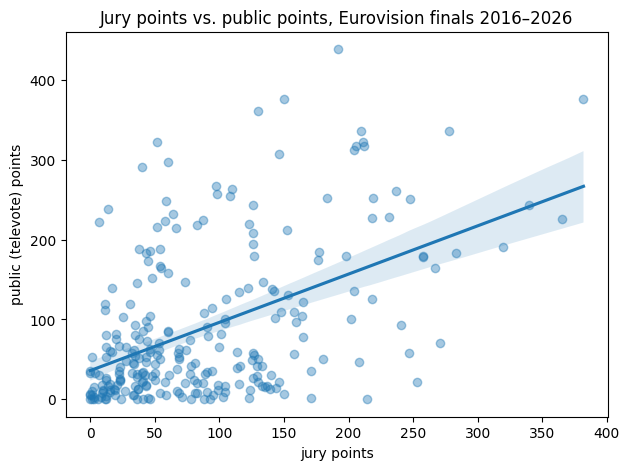

In [27]:
plt.figure(figsize=(7, 5))
sns.regplot(x='points_jury_final', y='points_tele_final', data=df_16, scatter_kws={'alpha': 0.4})
plt.title('Jury points vs. public points, Eurovision finals 2016–2026')
plt.xlabel('jury points')
plt.ylabel('public (televote) points')
plt.show()

`.corr()` on a whole table computes all pairwise correlations between numerical columns; a heatmap makes the matrix readable.

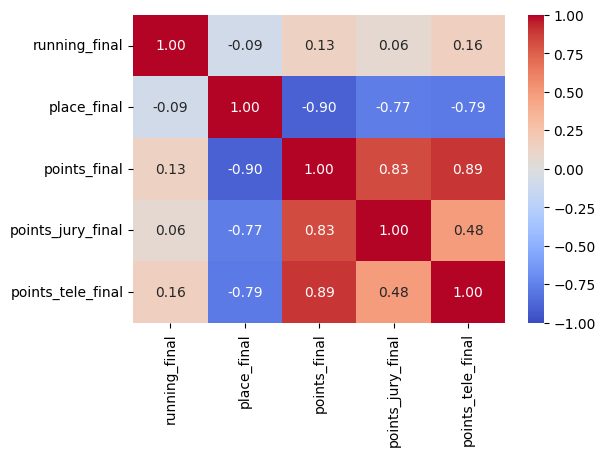

In [28]:
numeric = df_16[['running_final', 'place_final', 'points_final', 'points_jury_final', 'points_tele_final']]

plt.figure(figsize=(6, 4))
sns.heatmap(numeric.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

Correlation does not tell us who won. In 2024 the jury's first choice won the contest; what was its rank with the public? `.rank()` orders the values within a group.

In [29]:
final_2024 = df_16[df_16['year'] == 2024].copy()
final_2024['jury_rank']   = final_2024['points_jury_final'].rank(ascending=False)
final_2024['public_rank'] = final_2024['points_tele_final'].rank(ascending=False)
final_2024.sort_values('place_final')[['to_country', 'performer', 'song', 'place_final', 'points_jury_final', 'points_tele_final', 'jury_rank', 'public_rank']].head(6)

,to_country,performer,song,place_final,points_jury_final,points_tele_final,jury_rank,public_rank
1721,Switzerland,Nemo,The Code,1.0,365.0,226.0,1.0,5.0
1732,Croatia,Baby Lasagna,Rim Tim Tagi Dim,2.0,210.0,337.0,3.0,1.0
1743,Ukraine,alyona alyona & Jerry Heil,Teresa & Maria,3.0,146.0,307.0,5.0,3.0
1751,France,Slimane,Mon amour,4.0,218.0,227.0,2.0,4.0
1752,Israel,Eden Golan,Hurricane,5.0,52.0,323.0,12.0,2.0
1753,Ireland,Bambie Thug,Doomsday Blue,6.0,142.0,136.0,6.0,6.0


> **Methods note: one number for a cloud of points.** A correlation coefficient summarizes a whole scatter plot in a single number. Correlation does not say anything about outcomes: in 2024 the public's fifth choice won. When you report a correlation, say what the two variables are, on how many cases it is based, and what it leaves out.

### Does the running order matter? (RQ2)

Bruine de Bruin (2005) reports that later positions in the running order are advantageous. We can look at the relationship between `running_final` and `place_final` for all finals since 1975 (when the current points system was introduced).

In [30]:
df_fin = df_sel[(df_sel['year'] >= 1975) & df_sel['place_final'].notna() & df_sel['running_final'].notna()].copy()

print('correlation running order vs. final place (1975–2026):', round(df_fin['running_final'].corr(df_fin['place_final']), 2))

print('correlation running order vs. final place (1975–2012):', round(df_fin[df_fin['year'] <= 2012]['running_final'].corr(df_fin['place_final']), 2))
print('correlation running order vs. final place (2013–2026):', round(df_fin[df_fin['year'] >= 2013]['running_final'].corr(df_fin['place_final']), 2))

correlation running order vs. final place (1975–2026): -0.09
correlation running order vs. final place (1975–2012): -0.1
correlation running order vs. final place (2013–2026): -0.1


> **Methods note: it's complicated.** Since 2013 the producers allocate the running order and a slot late in the show may be given to songs that are expected to do well, or used to spread favourites. Correlation cannot separate the effect of the slot from the effect of the allocation. Studies of this question rely on years and contests in which the running order was drawn by lot, precisely because of this problem (before 2013), but the numbers basically stayed the same. We cannot easily answer this research question.

## 6. Categorical variables and grouping

`.groupby()` splits the table into groups based on the values in one or more columns, so that we can compute something per group. Think of it as a pivot table: "group my data by this column, then calculate something for each group". The result of `.groupby()` alone is just a Python object; we add an operation such as `.size()`, `.mean()`, or `.agg()`.

In [31]:
df_sel.groupby('to_country').size().sort_values(ascending=False).head(10)

,0
to_country,
Germany,71
France,70
Belgium,69
United Kingdom,69
Switzerland,68
Netherlands,67
Sweden,66
Spain,65
Norway,65


With `.agg()` we compute several values per group at once and name the resulting columns. Here: number of entries, number of victories (a small function that counts how often the place equals 1), and the mean final place.

In [32]:
def count_wins(places):
    return (places == 1).sum()

df_countries = df_sel.groupby('to_country').agg(
    entries=('year', 'size'),
    wins=('place_final', count_wins),
    mean_place=('place_final', 'mean')
)
df_countries.sort_values(['wins', 'mean_place'], ascending=[False, True]).head(10).round(1)

,entries,wins,mean_place
to_country,,,
Sweden,66,7,8.4
Ireland,59,7,8.8
Luxembourg,41,5,9.6
United Kingdom,69,5,10.1
France,70,5,10.1
Netherlands,67,5,10.5
Israel,49,4,9.8
Italy,53,3,7.2
Ukraine,22,3,8.1


Pandas plots directly from a Series or DataFrame; `kind='barh'` gives horizontal bars, which keep country names readable. We sort twice: once to pick the top 15, once more so that the largest bar ends up on top.

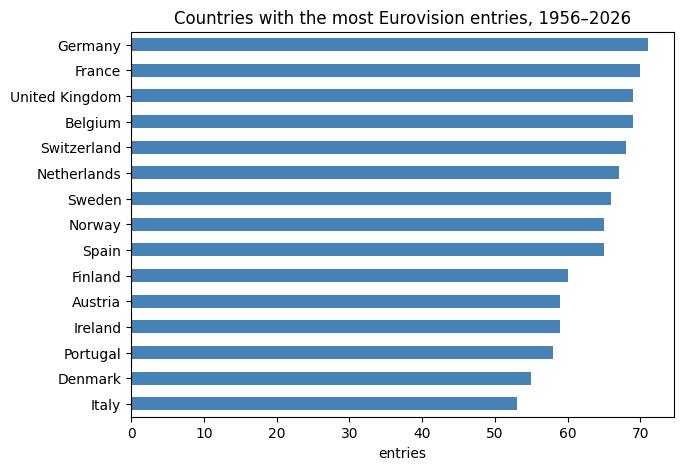

In [33]:
plt.figure(figsize=(7, 5))
df_countries['entries'].sort_values(ascending=False).head(15).sort_values().plot(kind='barh', color='steelblue')
plt.title('Countries with the most Eurovision entries, 1956–2026')
plt.xlabel('entries')
plt.ylabel('')
plt.show()

The same logic applies to our derived category. How many entries per language type, and how do the three groups fare in the final? Seaborn's violin plot shows the whole distribution of places per group rather than a single mean.

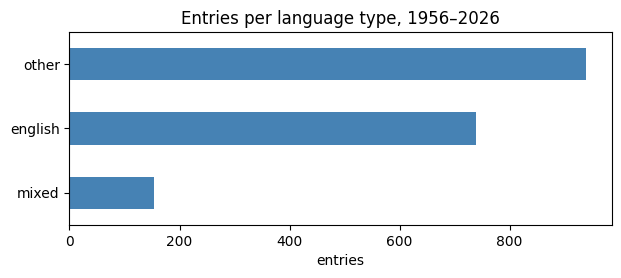

In [34]:
plt.figure(figsize=(7, 2.5))
df_sel.groupby('language_type').size().sort_values().plot(kind='barh', color='steelblue')
plt.title('Entries per language type, 1956–2026')
plt.xlabel('entries')
plt.ylabel('')
plt.show()

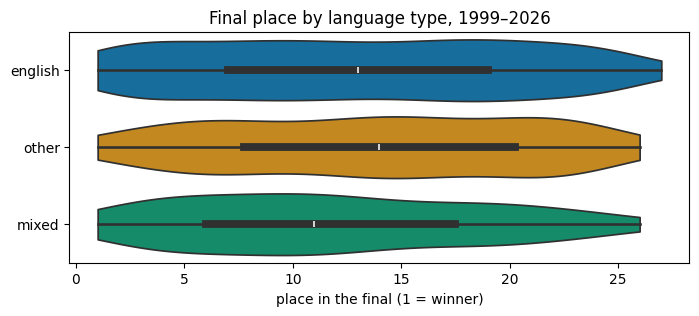

In [35]:
df_1999 = df_sel[(df_sel['year'] >= 1999) & df_sel['place_final'].notna()]

plt.figure(figsize=(8, 3))
sns.violinplot(data=df_1999, x='place_final', y='language_type', hue='language_type',
               inner='box', palette='colorblind', legend=False, cut=0)
plt.title('Final place by language type, 1999–2026')
plt.xlabel('place in the final (1 = winner)')
plt.ylabel('')
plt.show()

> **Methods note: group averages hide group sizes and time.** The mean place of a country compares Germany's 71 entries with the twelve of Australia; the mean place of "other" languages compares entries from 1956 with entries from 2026, and English was rare before 1999, so the language groups are also *period* groups. Always show counts next to averages, and ask whether the groups you compare lived in the same conditions.

## 7. Columns with several values: `explode()`

Some columns hold several values in one cell: `composers`, `lyricists`, and `writers` list names separated by `;` (recent years use `writers`, earlier years `composers` and `lyricists`). To count people, we first combine the three columns into one `credits` column (`fillna('')` turns missing values into empty text so that joining works), then split the cell into a list, and `explode()` gives every list element its own row.

In [36]:
credits = (df['composers'].fillna('') + ';' + df['lyricists'].fillna('') + ';' + df['writers'].fillna(''))
se_credits = credits.str.split(';').explode().str.strip()
se_credits = se_credits[se_credits != '']              # drop the empty pieces produced by missing values
se_credits.value_counts().head(15)

,count
Ralph Siegel,23
Thomas G:son,20
Dimitris Kontopoulos,18
Borislav Milanov,17
Gunter Johansen,15
Darko Dimitrov,13
Thomas Stengaard,12
Joacim Persson,11
Linnea Deb,10
Anderz Wrethov,9


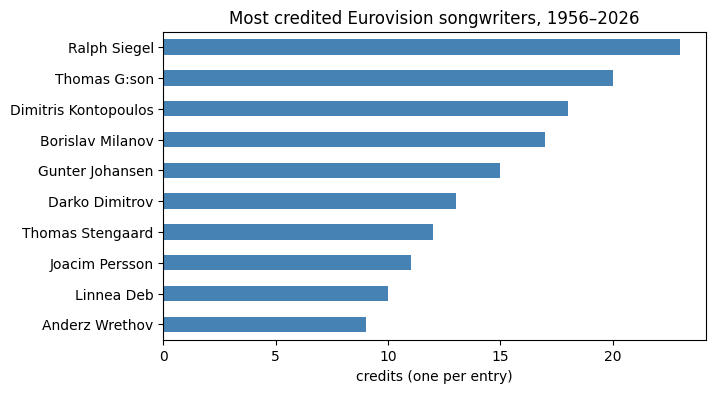

In [37]:
plt.figure(figsize=(7, 4))
se_credits.value_counts().head(10).sort_values().plot(kind='barh', color='steelblue')
plt.title('Most credited Eurovision songwriters, 1956–2026')
plt.xlabel('credits (one per entry)')
plt.ylabel('')
plt.show()

> **Methods note: explode changes the unit of analysis.** After `explode()`, a row is a *credit*, not an entry: a song with five writers weighs five times as much as a song with one. That is right for "who writes Eurovision?" and wrong for "how many entries did Ralph Siegel write?" unless duplicates per entry are removed first. Note also that the credit fields come from fan sources whose categories changed over time: older entries distinguish composers and lyricists, recent entries list "writers". The combined column hides that shift.

## 8. Time series

*(slides, part 3: dates and data types; RQ3)*

Grouping by year turns the table into a time series: a metric per interval. The simplest one is the number of entries per contest.

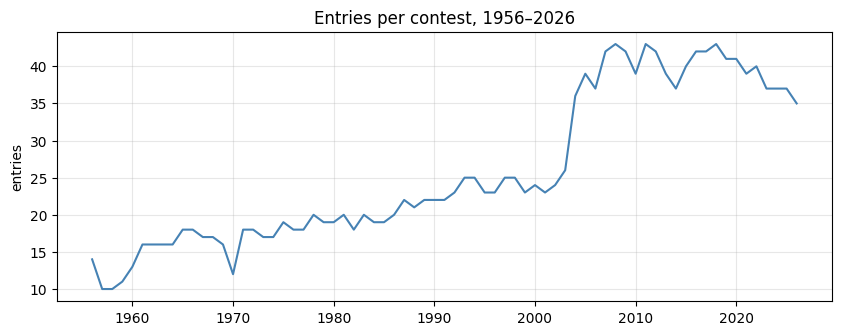

In [38]:
entries_per_year = df_sel.groupby('year').size()

plt.figure(figsize=(10, 3.5))
entries_per_year.plot(color='steelblue')
plt.title('Entries per contest, 1956–2026')
plt.ylabel('entries')
plt.xlabel('')
plt.grid(alpha=0.3)
plt.show()

> **Methods note: what is counted per interval?** The line shows 41 entries for 2020, a contest that never took place: the dataset records the songs that *were going to* compete. Whether that is right depends on the question (participation intentions versus performances). A time series inherits every decision about the unit of analysis.

RQ3: the share of entries sung in English per year. A boolean column (`True`/`False`) has a mean, which is the share of `True` values, so `groupby('year').mean()` gives us the share directly. The shaded area marks the years in which the rules required a national language (1966–1972 and 1977–1998); since 1999 the language is free.

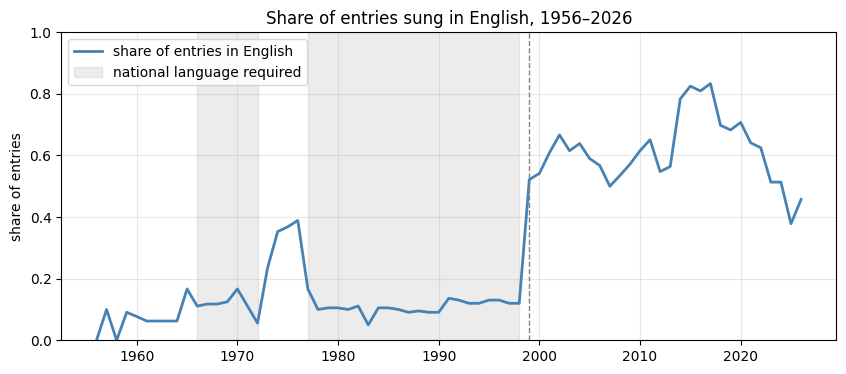

In [39]:
df_sel['is_english'] = df_sel['language_type'] == 'english'
share_english = df_sel.groupby('year')['is_english'].mean()

plt.figure(figsize=(10, 4))
share_english.plot(color='steelblue', linewidth=2, label='share of entries in English')
plt.axvspan(1966, 1972, color='grey', alpha=0.15)
plt.axvspan(1977, 1998, color='grey', alpha=0.15, label='national language required')
plt.axvline(1999, color='grey', linestyle='--', linewidth=1)
plt.title('Share of entries sung in English, 1956–2026')
plt.ylabel('share of entries')
plt.xlabel('')
plt.ylim(0, 1)
plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.show()

> **Methods note — periodization comes from outside the data.** The shaded years are an interpretive overlay: nothing in the table says "rule change", we added it from the contest's history, and it turns a wiggly line into a story (a jump in 1999, a peak around 2015, and a return of national languages in recent years). Without such context the line is just a line; with the wrong context it tells the wrong story. Document where your periodization comes from.

One more time series, to make a point about comparability: the maximum number of points awarded to an entry in each year.

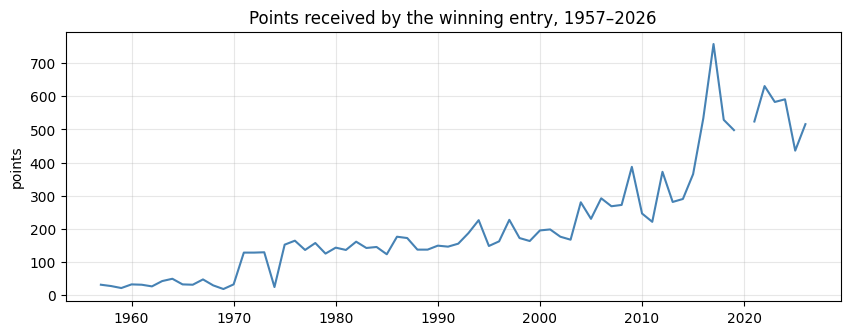

In [40]:
plt.figure(figsize=(10, 3.5))
df_sel.groupby('year')['points_final'].max().plot(color='steelblue')
plt.title('Points received by the winning entry, 1957–2026')
plt.ylabel('points')
plt.xlabel('')
plt.grid(alpha=0.3)
plt.show()

> **Methods note: comparability over time.** The winner's points rise from about 150 in the 1970s to over 500 after 2016 because more countries vote and every country has given two sets of points since 2016. Points are not comparable across years; places are only partly comparable (the number of finalists changed). Burgoyne et al. (2023) build a statistical model to express all results on one scale precisely because the raw numbers cannot be compared. When a measurement system changes, the data change with it, even if the column keeps its name.

## 9. Writing data back — and documenting it

*(slides, part 5: three pathways to visualization)*

It is often useful to save a manipulated table (cleaned, with new variables) to a file, for example to continue in another tool. `to_csv()` and `to_excel()` take a file path; `index=False` prevents the row numbers from being saved as a column. In Colab, files without a path go to the temporary `/content/` folder; use a Drive path to keep them.

In [41]:
df_sel.to_csv('eurovision_selection.csv', index=False, encoding='utf-8')
# df_sel.to_excel('eurovision_selection.xlsx', index=False)
# df_sel.to_csv('/content/drive/MyDrive/eurovision_selection.csv', index=False)

> **Methods note: document what you did.** A reader of `eurovision_selection.csv` cannot see any of the decisions made in this notebook: the source and its limits, the three language boxes, the merged lyric versions, the rows that are comparable and the ones that are not. Writing those down is part of the analysis. For the project report, the "data examination" section asks for exactly this kind of material: what the data contain, what they leave out, and what you did to them.

## Summary

* Data analysis in the humanities asks informed questions about cultural data, digitized or born digital. Today the questions came from a small research literature on Eurovision, and they decided which columns we built, which rows we compared, and which numbers we trusted.
* Pandas provides the practical means: `read_csv`, `head`, `info`, `isna`, `to_datetime`, column selection, derived variables with `apply`, filters with conditions, `describe`, `corr`, `groupby` with `size`, `mean`, and `agg`, `explode`, time series by year, and `to_csv`.
* Every step had a methods layer: the unit of analysis, the history of missing values, operationalization, categorization, the limits of string matching and of correlation, group sizes, periodization, and comparability over time. These are the notes you will be asked to write in your own words during assignments.
* To come to grips with Pandas, do as many practical exercises as possible; the [Pandas cheat sheet](https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf) and the [documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) are your friends.